# **Project Name**    -  Amazon Prime TV Shows & Movies: Exploratory Data Analysis

##### **Project Type**    - EDA (with bonus: Dashboard app and Classification model)
##### **Contribution**    - Individual
##### **Team Member 1 -** *(write your name here)*

# **Project Summary -**

Streaming platforms compete on the breadth and freshness of their content libraries. This project analyses the Amazon Prime Video catalogue available in the United States to understand **what the library contains, where it comes from, how it has changed over time and which content is rated best**. The analysis uses two files: `titles.csv` (9,871 titles, 15 columns) and `credits.csv` (124,235 cast and crew records).

**Data preparation.** Only 3 exact duplicate titles and 56 duplicate credit rows were found and removed, leaving 9,868 unique titles. List-like text columns (genres, production countries) were parsed into real Python lists, categorical text was standardised (type, genre, country codes, age certification), and the release year was converted to a datetime. Missing values were treated column by column instead of being dropped: 65.7% of titles have no age certification (labelled *Not Rated*), `seasons` is empty for every movie by design, and the IMDb and TMDB score columns are missing for 10.3% and 21.1% of titles and were kept as NaN for the EDA (median imputation is used only inside the ML pipeline).

**Key findings.**
1. The catalogue is movie-heavy: 8,511 movies (86.2%) against 1,357 TV shows (13.8%).
2. Growth is recent. 60.4% of titles were released in 2010 or later and yearly releases rose from 185 in 2010 to a peak of 856 in 2021.
3. Drama (4,762 titles) and Comedy (2,987) dominate, followed by Thriller, Action and Romance. Movies lean towards Thriller, Horror and Romance, while TV shows over-index on Animation, Documentary, Family and Reality.
4. The United States accounts for 54.0% of titles. India is the second-largest source (1,072 titles) but almost entirely in movies (1034 movies vs 38 shows).
5. Rating information is sparse (65.7% not rated). Among rated titles, mature ratings dominate: R for movies and TV-MA/TV-14 for shows, and the TV-MA share of rated shows grew from 9.6% in the 2000s to 36.0% in the 2010s.
6. TV shows have a higher average IMDb score (7.12) than movies (5.8), and 53.6% of shows have only one season.
7. Movies have a median runtime of 91 minutes; 630 movies fall outside the IQR fences (42 to 142 minutes).

**Bonus work.** A Streamlit dashboard (`app.py`) lets users filter the cleaned data interactively, and three classification models were trained to predict Movie vs TV Show. The best model (Random Forest, without rating features) reaches an F1 of 0.917 for TV shows and ROC-AUC of 0.994, with runtime being by far the most important feature.

**Recommendations.** Increase the share of original and licensed series, invest in Indian-language series and UK/Japanese content for shows, build a stronger family and animation line-up, complete the age-certification metadata and use seasonal themes such as Christmas for targeted campaigns.

# **GitHub Link -**

*(Paste your GitHub link here.)*

# **Problem Statement**

**This dataset lists the movies and TV shows available on Amazon Prime Video (US) and the cast and crew behind them. The goal is to extract insights on content diversity, regional availability, trends over time, and ratings and popularity, so that content acquisition, production and recommendation decisions can be made from data.**

#### **Define Your Business Objective?**

Help Amazon Prime Video understand the structure of its catalogue and use that knowledge to:
* decide the right balance between **movies and TV shows**,
* choose which **genres and regions** to acquire or produce more of,
* improve **age-rating metadata** and audience targeting,
* identify **quality signals** (IMDb / TMDB scores) and stable patterns that can feed recommendations.

# **Assignment Task Map**

| Assignment task | Where in this notebook |
|---|---|
| Task 1 Loading and exploration | Section 1 and 2 |
| Task 2 Data cleaning | Section 3 (functions + summary) |
| Task 3 Content types | Chart 1 |
| Task 4 Release year | Chart 2 |
| Task 5 Genre distribution | Chart 3 |
| Task 6 Ratings | Chart 4 |
| Task 7 Content type by rating | Chart 5 |
| Task 8 Genre by type | Chart 6 |
| Task 9 Country-wise | Chart 7 |
| Task 10 Year vs Genre heatmap | Chart 8 |
| Task 11 Release over time by type | Chart 9 |
| Task 12 Rating trends | Chart 10 |
| Task 13 Directors and actors | Charts 11 and 12 |
| Task 14 Duration analysis | Chart 13 |
| Task 15 Keyword analysis (bonus) | Charts 17 and 18 |
| Task 16 and 17 Findings and recommendations | Section 5 |
| Task 18 Dashboard (bonus) | `app.py` (Streamlit), Section 6 |
| Task 19 Predictive model (bonus) | Section 7 |

# ***Let's Begin !***

## ***1. Know Your Data***

*Place `titles.csv` and `credits.csv` in the same folder as this notebook (or upload them in Colab).*

### Import Libraries

In [1]:
# Import Libraries
import ast, re, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 14, "axes.titleweight": "bold",
                     "axes.labelsize": 11})

# Amazon Prime inspired palette, used consistently for Movie vs TV Show
TYPE_COLORS = {"Movie": "#00A8E1", "TV Show": "#FF9900"}
PRIME_BLUE, PRIME_ORANGE, PRIME_NAVY = "#00A8E1", "#FF9900", "#232F3E"

### Dataset Loading

In [2]:
# Load Dataset (titles.csv = catalog, credits.csv = cast & crew)
titles  = pd.read_csv("titles.csv")
credits = pd.read_csv("credits.csv")
print("titles :", titles.shape)
print("credits:", credits.shape)

titles : (9871, 15)
credits: (124235, 5)


### Dataset First View (Task 1: first 10 rows)

In [3]:
# Dataset First Look (Task 1: first 10 rows)
titles.head(10)

,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
0,ts20945,The Three Stooges,SHOW,The Three Stooges were an American vaudeville ...,1934,TV-PG,19,"['comedy', 'family', 'animation', 'action', 'f...",['US'],26.0,tt0850645,8.6,1092.0,15.424,7.6
1,tm19248,The General,MOVIE,"During America’s Civil War, Union spies steal ...",1926,NaN,78,"['action', 'drama', 'war', 'western', 'comedy'...",['US'],NaN,tt0017925,8.2,89766.0,8.647,8.0
2,tm82253,The Best Years of Our Lives,MOVIE,It's the hope that sustains the spirit of ever...,1946,NaN,171,"['romance', 'war', 'drama']",['US'],NaN,tt0036868,8.1,63026.0,8.435,7.8
3,tm83884,His Girl Friday,MOVIE,"Hildy, the journalist former wife of newspaper...",1940,NaN,92,"['comedy', 'drama', 'romance']",['US'],NaN,tt0032599,7.8,57835.0,11.270,7.4
4,tm56584,In a Lonely Place,MOVIE,An aspiring actress begins to suspect that her...,1950,NaN,94,"['thriller', 'drama', 'romance']",['US'],NaN,tt0042593,7.9,30924.0,8.273,7.6
5,tm160494,Stagecoach,MOVIE,A group of people traveling on a stagecoach fi...,1939,NaN,96,"['western', 'drama']",['US'],NaN,tt0031971,7.8,48149.0,11.786,7.7
6,tm87233,It's a Wonderful Life,MOVIE,A holiday favourite for generations... George...,1946,PG,130,"['drama', 'family', 'fantasy', 'romance', 'com...",['US'],NaN,tt0038650,8.6,444243.0,26.495,8.3
7,tm19424,Detour,MOVIE,"The life of Al Roberts, a pianist in a New Yor...",1945,NaN,66,"['thriller', 'drama', 'crime']",['US'],NaN,tt0037638,7.3,17233.0,7.757,7.2
8,tm116781,My Man Godfrey,MOVIE,"Fifth Avenue socialite Irene Bullock needs a ""...",1936,NaN,95,"['comedy', 'romance', 'drama']",['US'],NaN,tt0028010,8.0,23532.0,8.633,7.6
9,tm112005,Marihuana,MOVIE,A young girl named Burma attends a beach party...,1936,NaN,57,"['crime', 'drama']",['US'],NaN,tt0026683,4.0,864.0,3.748,3.6


### Dataset Rows & Columns count

In [4]:
# Dataset Rows & Columns count
print(f"Titles  -> rows: {titles.shape[0]:,} | columns: {titles.shape[1]}")
print(f"Credits -> rows: {credits.shape[0]:,} | columns: {credits.shape[1]}")

Titles  -> rows: 9,871 | columns: 15
Credits -> rows: 124,235 | columns: 5


### Dataset Information

In [5]:
# Dataset Info (data types and non-null counts)
titles.info()

<class 'pandas.DataFrame'>
RangeIndex: 9871 entries, 0 to 9870
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    9871 non-null   str    
 1   title                 9871 non-null   str    
 2   type                  9871 non-null   str    
 3   description           9752 non-null   str    
 4   release_year          9871 non-null   int64  
 5   age_certification     3384 non-null   str    
 6   runtime               9871 non-null   int64  
 7   genres                9871 non-null   str    
 8   production_countries  9871 non-null   str    
 9   seasons               1357 non-null   float64
 10  imdb_id               9204 non-null   str    
 11  imdb_score            8850 non-null   float64
 12  imdb_votes            8840 non-null   float64
 13  tmdb_popularity       9324 non-null   float64
 14  tmdb_score            7789 non-null   float64
dtypes: float64(5), int64(2), str(8)


#### Duplicate Values

In [6]:
# Dataset Duplicate Value Count
print("Duplicate rows in titles :", titles.duplicated().sum())
print("Duplicate rows in credits:", credits.duplicated().sum())
print("Duplicate title ids      :", titles["id"].duplicated().sum())

Duplicate rows in titles : 3
Duplicate rows in credits: 56
Duplicate title ids      : 3


#### Missing Values/Null Values

In [7]:
# Missing Values / Null Values Count
missing = titles.isnull().sum().to_frame("missing_count")
missing["missing_%"] = (missing["missing_count"] / len(titles) * 100).round(2)
missing[missing["missing_count"] > 0].sort_values("missing_count", ascending=False)

,missing_count,missing_%
seasons,8514,86.25
age_certification,6487,65.72
tmdb_score,2082,21.09
imdb_votes,1031,10.44
imdb_score,1021,10.34
imdb_id,667,6.76
tmdb_popularity,547,5.54
description,119,1.21


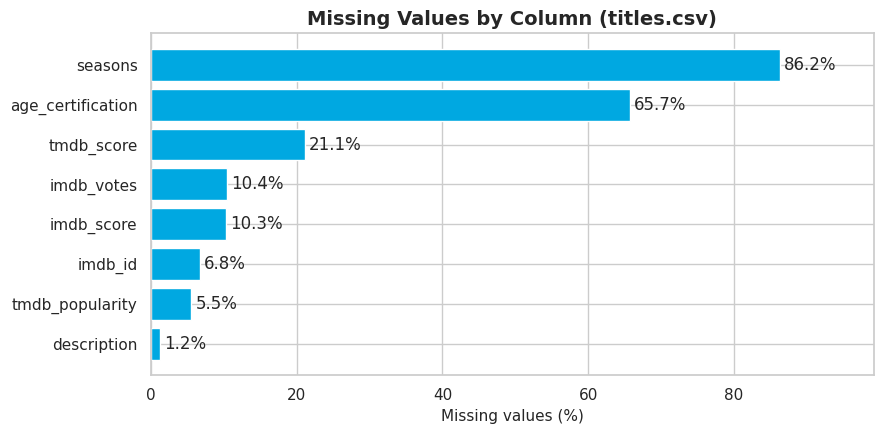

In [8]:
# Visualizing the missing values
miss = missing[missing["missing_count"] > 0].sort_values("missing_%")
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(miss.index, miss["missing_%"], color=PRIME_BLUE)
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_xlabel("Missing values (%)"); ax.set_title("Missing Values by Column (titles.csv)")
ax.set_xlim(0, miss["missing_%"].max() * 1.15)
plt.tight_layout(); plt.show()

### What did you know about your dataset?

* `titles.csv` has **9,871 rows and 15 columns**; `credits.csv` has **124,235 rows and 5 columns**.
* Only **3 duplicate titles** and **56 duplicate credit rows** exist, so the data is already quite clean.
* The data mixes categorical columns (`type`, `age_certification`, `genres`, `production_countries`) and numeric columns (`release_year`, `runtime`, `seasons`, scores, votes, popularity).
* `genres` and `production_countries` are stored as *text that looks like a list* and must be parsed before analysis.
* **Missing values:** `seasons` (86.3%) is empty for all movies by design, `age_certification` is missing for 65.7% of titles, `tmdb_score` 21.1%, `imdb_score` 10.3%, `imdb_votes` 10.4%, `tmdb_popularity` 5.5% and `description` 1.2%.
* There is **no full date column**: only `release_year`, so it is converted to a datetime for time-based work.

## ***2. Understanding Your Variables***

In [9]:
# Dataset Columns
list(titles.columns)

['id', 'title', 'type', 'description', 'release_year', 'age_certification', 'runtime', 'genres', 'production_countries', 'seasons', 'imdb_id', 'imdb_score', 'imdb_votes', 'tmdb_popularity', 'tmdb_score']

In [10]:
# Task 1: .describe() for numeric and categorical columns
display(titles.describe().round(2))
titles.describe(include="object").T[["count", "unique", "top", "freq"]]

,release_year,runtime,seasons,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
count,9871.00,9871.00,1357.00,8850.00,8840.00,9324.00,7789.00
mean,2001.33,85.97,2.79,5.98,8533.61,6.91,5.98
std,25.81,33.51,4.15,1.34,45920.15,30.00,1.52
min,1912.00,1.00,1.00,1.10,5.00,0.00,0.80
25%,1995.50,65.00,1.00,5.10,117.00,1.23,5.10
50%,2014.00,89.00,1.00,6.10,462.50,2.54,6.00
75%,2018.00,102.00,3.00,6.90,2236.25,5.63,6.90
max,2022.00,549.00,51.00,9.90,1133692.00,1437.91,10.00


,count,unique,top,freq
id,9871,9868,tm89134,2
title,9871,9737,The Lost World,3
type,9871,2,MOVIE,8514
description,9752,9734,No overview found.,5
age_certification,3384,11,R,1249
genres,9871,2028,['drama'],908
production_countries,9871,497,['US'],4810
imdb_id,9204,9201,tt0033683,2


### Variables Description

| Column | Description |
|---|---|
| `id` | Title ID on JustWatch (join key with credits) |
| `title` | Name of the title |
| `type` | MOVIE or SHOW |
| `description` | Short description |
| `release_year` | Year of release |
| `age_certification` | Age rating (MPAA for movies, TV Parental Guidelines for shows) |
| `runtime` | Length in minutes (movie length, or episode length for shows) |
| `genres` | List of genres |
| `production_countries` | List of country codes that produced the title |
| `seasons` | Number of seasons (shows only) |
| `imdb_id`, `imdb_score`, `imdb_votes` | IMDb identifier, score and number of votes |
| `tmdb_popularity`, `tmdb_score` | TMDB popularity and score |
| `person_id`, `name`, `character`, `role` | (credits.csv) person, name, character played and ACTOR / DIRECTOR role |

### Check Unique Values for each variable.

In [11]:
# Check Unique Values for each variable
pd.DataFrame({"dtype": titles.dtypes.astype(str), "unique_values": titles.nunique(),
              "missing": titles.isnull().sum()})

,dtype,unique_values,missing
id,str,9868,0
title,str,9737,0
type,str,2,0
description,str,9734,119
release_year,int64,110,0
age_certification,str,11,6487
runtime,int64,207,0
genres,str,2028,0
production_countries,str,497,0
seasons,float64,32,8514


## 3. ***Data Wrangling*** (Task 2: Data Cleaning)

### Data Wrangling Code

In [12]:
# ---------- Data Wrangling: reusable, modular cleaning functions ----------
GENRE_MAP = {"scifi": "Sci-Fi", "documentation": "Documentary"}   # friendlier display names
MOVIE_RATINGS = ["G", "PG", "PG-13", "R", "NC-17"]
TV_RATINGS = ["TV-Y", "TV-Y7", "TV-G", "TV-PG", "TV-14", "TV-MA"]

def parse_list(value):
    """Safely convert a string such as "['drama', 'comedy']" into a Python list."""
    try:
        return ast.literal_eval(value)
    except (ValueError, SyntaxError):
        return []

def clean_genres(value):
    items = [g.strip().lower() for g in parse_list(value)]
    items = [GENRE_MAP.get(g, g.title()) for g in items]
    return items if items else ["Unknown"]

def clean_countries(value):
    items = [c.strip().upper() for c in parse_list(value)]
    return items if items else ["Unknown"]

def clean_titles(raw):
    """Return an analysis-ready copy of titles.csv."""
    d = raw.copy()
    d = d.drop_duplicates()                                           # 1. remove duplicates
    d["title"] = d["title"].str.strip()                               # 2. standardise text
    d["type"] = d["type"].str.strip().str.upper().map({"MOVIE": "Movie", "SHOW": "TV Show"})
    d["age_certification"] = d["age_certification"].str.strip().str.upper().fillna("Not Rated")
    d["description"] = d["description"].fillna("No description available")
    d["genres_list"] = d["genres"].apply(clean_genres)                # 3. parse list columns
    d["countries_list"] = d["production_countries"].apply(clean_countries)
    d["primary_genre"] = d["genres_list"].str[0]
    d["primary_country"] = d["countries_list"].str[0]
    d["n_genres"] = d["genres_list"].apply(lambda x: 0 if x == ["Unknown"] else len(x))
    # 4. dates: the dataset only has a release YEAR, so convert it to a real datetime
    d["release_date"] = pd.to_datetime(d["release_year"].astype(str), format="%Y")
    d["decade"] = (d["release_year"] // 10) * 10
    return d.reset_index(drop=True)

def clean_credits(raw, valid_ids):
    c = raw.drop_duplicates().copy()
    c["name"] = c["name"].str.strip()
    c["role"] = c["role"].str.strip().str.title()
    c["character"] = c["character"].fillna("Unknown")
    return c[c["id"].isin(valid_ids)].reset_index(drop=True)

df   = clean_titles(titles)
cred = clean_credits(credits, df["id"])
print(f"titles  : {titles.shape} -> {df.shape}")
print(f"credits : {credits.shape} -> {cred.shape}")

titles  : (9871, 15) -> (9868, 22)
credits : (124235, 5) -> (124179, 5)


In [13]:
# Quick check of the cleaned data
print("Remaining duplicates:", df.duplicated(subset="id").sum())
print(df["type"].value_counts().to_dict())
print(df["age_certification"].value_counts().to_dict())
df[["title", "type", "release_year", "release_date", "age_certification", "genres_list", "countries_list"]].head()

Remaining duplicates: 0
{'Movie': 8511, 'TV Show': 1357}
{'Not Rated': 6484, 'R': 1249, 'PG-13': 588, 'PG': 582, 'G': 269, 'TV-MA': 217, 'TV-14': 188, 'TV-PG': 91, 'TV-Y': 78, 'TV-G': 57, 'TV-Y7': 52, 'NC-17': 13}


,title,type,release_year,release_date,age_certification,genres_list,countries_list
0,The Three Stooges,TV Show,1934,1934-01-01,TV-PG,"[Comedy, Family, Animation, Action, Fantasy, H...",[US]
1,The General,Movie,1926,1926-01-01,Not Rated,"[Action, Drama, War, Western, Comedy, European]",[US]
2,The Best Years of Our Lives,Movie,1946,1946-01-01,Not Rated,"[Romance, War, Drama]",[US]
3,His Girl Friday,Movie,1940,1940-01-01,Not Rated,"[Comedy, Drama, Romance]",[US]
4,In a Lonely Place,Movie,1950,1950-01-01,Not Rated,"[Thriller, Drama, Romance]",[US]


In [14]:
# Export the cleaned datasets (list columns are joined into readable strings)
out = df.copy()
out["genres"] = out["genres_list"].str.join(", ")
out["production_countries"] = out["countries_list"].str.join(", ")
out = out.drop(columns=["genres_list", "countries_list"])
out.to_csv("titles_cleaned.csv", index=False)
cred.to_csv("credits_cleaned.csv", index=False)
print("Saved titles_cleaned.csv", out.shape, "and credits_cleaned.csv", cred.shape)

Saved titles_cleaned.csv (9868, 20) and credits_cleaned.csv (124179, 5)


In [15]:
# Helper tables: one row per (title, genre) and per (title, country)
gx = df.explode("genres_list").rename(columns={"genres_list": "genre"})
gx = gx[gx["genre"] != "Unknown"]
cx = df.explode("countries_list").rename(columns={"countries_list": "country"})
cx = cx[cx["country"] != "Unknown"]
movies, shows = df[df["type"] == "Movie"], df[df["type"] == "TV Show"]
print(len(gx), "title-genre pairs |", len(cx), "title-country pairs")

22060 title-genre pairs | 10248 title-country pairs


### What all manipulations have you done and insights you found?

**Summary of data cleaning steps**

| # | Step | Decision and reason |
|---|---|---|
| 1 | Duplicates | Removed 3 duplicate title rows and 56 duplicate credit rows (9,871 to 9,868 titles). |
| 2 | Text standardisation | Trimmed whitespace, mapped `MOVIE`/`SHOW` to `Movie`/`TV Show`, upper-cased country codes and ratings, title-cased genres (`scifi` to `Sci-Fi`, `documentation` to `Documentary`). |
| 3 | List columns | Parsed `genres` and `production_countries` with `ast.literal_eval`; empty lists became `Unknown`. |
| 4 | Dates | Only a release year exists, so `release_date` (datetime) and `decade` were created. |
| 5 | Missing categorical | `age_certification` NaN to `Not Rated` (65.7% of titles) and `description` NaN to a placeholder text. |
| 6 | Missing numeric | `seasons` is NaN for movies by design; IMDb/TMDB fields stay NaN in the EDA (imputing scores would invent data). The ML pipeline uses median imputation. |
| 7 | New features | `primary_genre`, `primary_country`, `n_genres`, `decade`. |
| 8 | Credits | Kept only credits whose title exists in the cleaned titles table. |

**Cleaned datasets** are exported as `titles_cleaned.csv` and `credits_cleaned.csv`.

**Insight:** because most columns are fully populated, the main data-quality issue is the metadata gap in age certification, not duplicates.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1: Content Type: Movies vs TV Shows (Task 3)

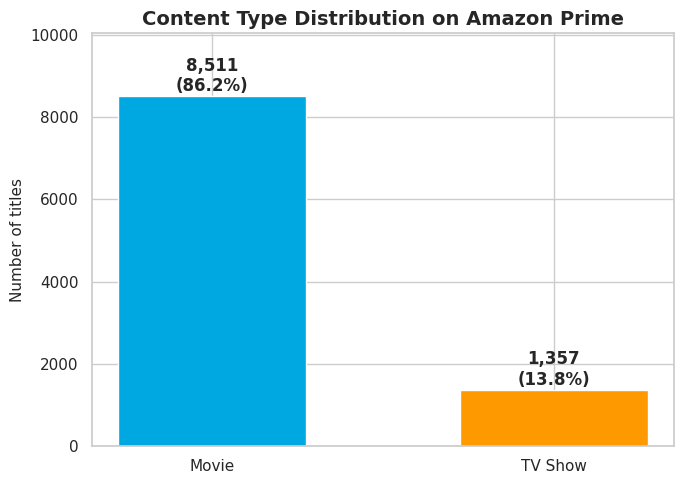

In [16]:
# Chart - 1: Movies vs TV Shows (Task 3)
counts = df["type"].value_counts()
fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(counts.index, counts.values, color=[TYPE_COLORS[t] for t in counts.index], width=0.55)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 120, f"{v:,}\n({v / len(df):.1%})", ha="center", fontweight="bold")
ax.set_ylim(0, counts.max() * 1.18)
ax.set_title("Content Type Distribution on Amazon Prime"); ax.set_ylabel("Number of titles"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?
A bar chart is the clearest way to compare the size of two categories, and labelling counts and percentages gives the exact split at a glance.

##### 2. What is/are the insight(s) found from the chart?
Movies make up **8,511 titles (86.2%)** and TV shows only **1,357 (13.8%)**: roughly **6.3 movies for every show**.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a deep movie library gives broad one-off appeal and strong choice for casual viewers.

**Negative / risk:** series drive binge-watching, renewals and long-term retention, so a catalogue with only about one show in seven may be weaker at keeping subscribers engaged.

#### Chart - 2: Number of Titles by Release Year (Task 4)

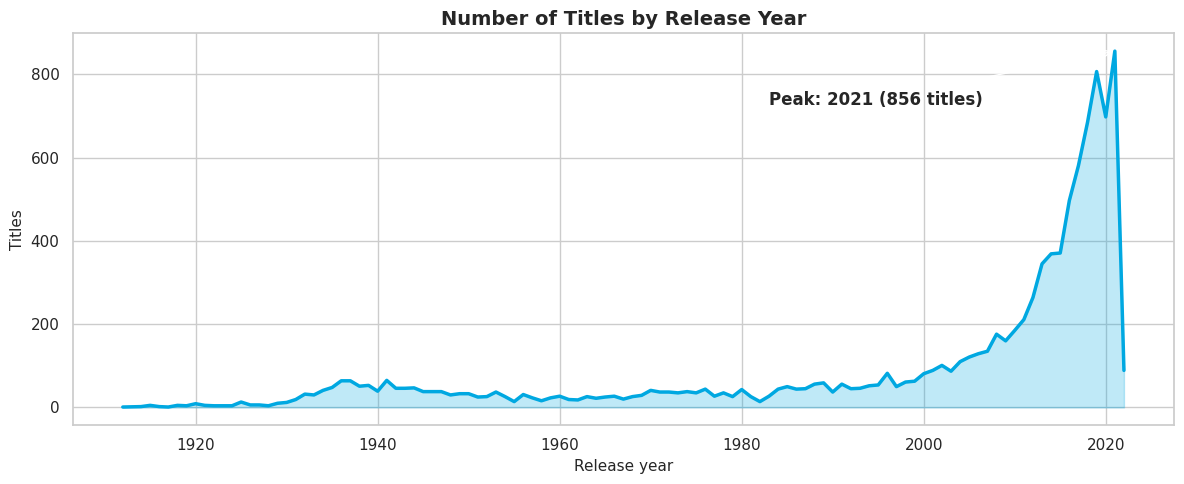

In [17]:
# Chart - 2: Releases per year (Task 4)
per_year = df["release_year"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(12, 5))
ax.fill_between(per_year.index, per_year.values, color=PRIME_BLUE, alpha=0.25)
ax.plot(per_year.index, per_year.values, color=PRIME_BLUE, lw=2.5)
peak = per_year[per_year.index < 2022].idxmax()
ax.annotate(f"Peak: {peak} ({per_year[peak]} titles)", xy=(peak, per_year[peak]),
            xytext=(peak - 38, per_year[peak] * 0.85), arrowprops=dict(arrowstyle="->"), fontweight="bold")
ax.set_title("Number of Titles by Release Year"); ax.set_xlabel("Release year"); ax.set_ylabel("Titles")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?
A line (area) chart suits a continuous time axis and makes growth, peaks and gaps easy to see.

##### 2. What is/are the insight(s) found from the chart?
The catalogue is dominated by recent content: **72.4%** of titles were released from 2000 onwards and **60.4%** from 2010 onwards. Yearly releases grew from **185 in 2010 to a peak of 856 in 2021**. The drop in 2022 (89 titles) reflects a **partial year**, not a real decline. About **17.9%** of titles are from before 1980.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a fresh, fast-growing library supports acquisition of recent releases.

**Negative / risk:** the older back-catalogue (about 18% of titles) probably has low engagement, so it adds volume rather than value unless it is curated.

#### Chart - 3: Top 10 Genres (Task 5)

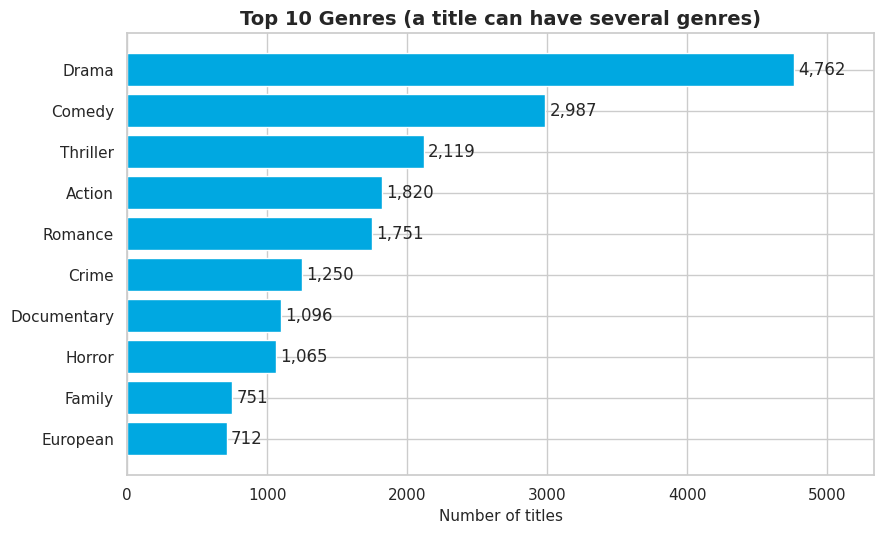

In [18]:
# Chart - 3: Top 10 genres (Task 5)
top_genres = gx["genre"].value_counts().head(10).sort_values()
fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.barh(top_genres.index, top_genres.values, color=PRIME_BLUE)
ax.bar_label(bars, labels=[f"{v:,}" for v in top_genres.values], padding=3)
ax.set_xlim(0, top_genres.max() * 1.12)
ax.set_title("Top 10 Genres (a title can have several genres)"); ax.set_xlabel("Number of titles")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?
A horizontal bar chart handles long category names well and ranks genres clearly. A title can carry several genres, so counts overlap.

##### 2. What is/are the insight(s) found from the chart?
**Drama** is the leading genre (4,762 titles, tagged on 48.3% of all titles), followed by **Comedy** (2,987), **Thriller** (2,119), **Action** (1,820) and **Romance** (1,751).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the library is anchored in the most-watched genres, which supports reach.

**Negative / risk:** these genres are crowded across all streaming services, so Prime needs distinctive titles inside them (or under-served genres) to stand out.

#### Chart - 4: Frequency of Content Ratings (Task 6)

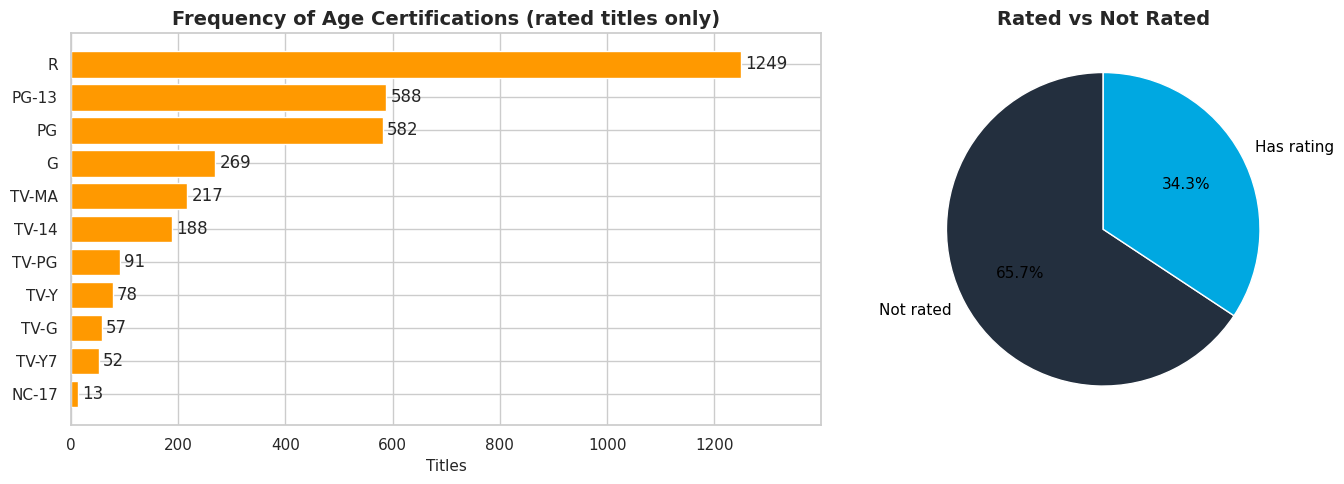

In [19]:
# Chart - 4: Content ratings (Task 6)
rated = df[df["age_certification"] != "Not Rated"]["age_certification"].value_counts().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.6, 1]})
bars = axes[0].barh(rated.index, rated.values, color=PRIME_ORANGE)
axes[0].bar_label(bars, padding=3); axes[0].set_xlim(0, rated.max() * 1.12)
axes[0].set_title("Frequency of Age Certifications (rated titles only)"); axes[0].set_xlabel("Titles")
share = (df["age_certification"] == "Not Rated").value_counts().rename({True: "Not rated", False: "Has rating"})
axes[1].pie(share.values, labels=share.index, autopct="%1.1f%%", startangle=90,
            colors=[PRIME_NAVY, PRIME_BLUE], textprops={"color": "black", "fontsize": 11},
            wedgeprops={"edgecolor": "white"})
axes[1].set_title("Rated vs Not Rated")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?
A horizontal bar chart ranks the rating categories, and a pie chart shows the large share of titles without any rating.

##### 2. What is/are the insight(s) found from the chart?
**65.7% of titles have no age certification.** Among the 3,384 rated titles, **R is the most common (1,249)**, followed by PG-13 (588), PG (582), G (269) and TV-MA (217).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** knowing the rating mix helps plan parental controls and audience targeting.

**Negative / risk:** with two thirds of the catalogue unrated, parental controls, regional compliance and content filtering are weak. Completing this metadata is a clear improvement.

#### Chart - 5: Age Certification by Content Type (Task 7)

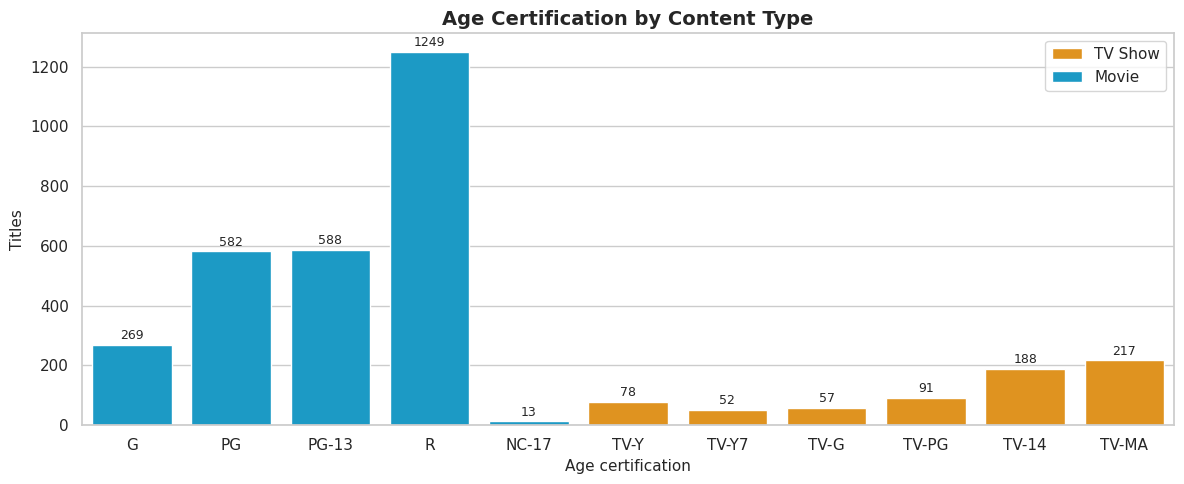

In [20]:
# Chart - 5: Rating by content type (Task 7)
order = MOVIE_RATINGS + TV_RATINGS
fig, ax = plt.subplots(figsize=(12, 5))
sns.countplot(data=df[df["age_certification"] != "Not Rated"], x="age_certification", hue="type",
              order=order, palette=TYPE_COLORS, ax=ax)
for c in ax.containers:
    ax.bar_label(c, padding=2, fontsize=9)
ax.set_title("Age Certification by Content Type"); ax.set_xlabel("Age certification"); ax.set_ylabel("Titles")
ax.legend(title="")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?
A grouped bar chart compares each rating across the two content types side by side.

##### 2. What is/are the insight(s) found from the chart?
Movies and shows use **different rating systems with no overlap**: movies carry G/PG/PG-13/R/NC-17 and shows carry TV-Y to TV-MA. Mature ratings dominate both: R for movies (1,249) and TV-MA (217) and TV-14 (188) for shows. Kids ratings are small (TV-Y 78, TV-Y7 52, TV-G 57). 68.3% of movies and 49.7% of shows are not rated.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** a mature-audience skew suits adult viewers and prestige drama.

**Negative / risk:** the limited kids and family certification suggests under-investment in a segment that supports household subscriptions. (Also note that rating alone nearly identifies the content type, which matters for the ML section.)

#### Chart - 6: Genre Dominance in Movies vs TV Shows (Task 8)

Share (%) of each type's titles for genres outside the top 10:
type       Movie  TV Show
genre                    
Animation    2.2     21.3
Reality      0.0     10.0
Sci-Fi       6.2     13.0


type,Movie,TV Show
genre,,
Drama,49.6,39.6
Comedy,30.0,31.8
Thriller,23.3,9.9
Action,19.2,13.9
Romance,19.0,9.7
Crime,12.9,11.4
Documentary,10.1,17.7
Horror,11.9,3.7
Family,6.2,16.4


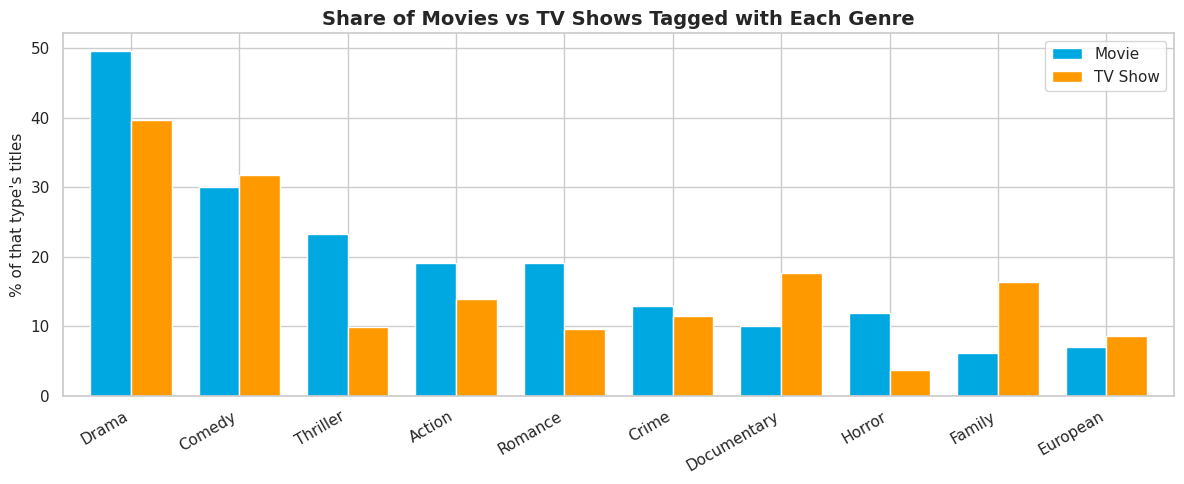

In [21]:
# Chart - 6: Which genres dominate Movies vs TV Shows? (Task 8)
top10 = gx["genre"].value_counts().head(10).index
type_totals = df["type"].value_counts()
share = (gx[gx["genre"].isin(top10)].groupby(["genre", "type"])["id"].nunique().unstack(fill_value=0))
share_pct = share.div(type_totals, axis=1) * 100            # % of each type's titles carrying the genre
share_pct = share_pct.loc[top10]
share_pct.plot(kind="bar", color=[TYPE_COLORS["Movie"], TYPE_COLORS["TV Show"]], figsize=(12, 5), width=0.75)
plt.title("Share of Movies vs TV Shows Tagged with Each Genre"); plt.ylabel("% of that type's titles")
plt.xlabel(""); plt.xticks(rotation=30, ha="right"); plt.legend(title="")
plt.tight_layout(); plt.show()
extra = gx[gx["genre"].isin(["Animation", "Reality", "Sci-Fi"])].groupby(["genre", "type"])["id"].nunique().unstack(fill_value=0)
print("Share (%) of each type's titles for genres outside the top 10:")
print((extra.div(type_totals, axis=1) * 100).round(1))
share_pct.round(1)

##### 1. Why did you pick the specific chart?
A grouped bar chart of **percentages** is fairer than raw counts, because there are 6 times more movies than shows.

##### 2. What is/are the insight(s) found from the chart?
Movies lean towards **Drama (49.6% vs 39.6%), Thriller (23.3% vs 9.9%), Romance (19.0% vs 9.7%) and Horror (11.9% vs 3.7%)**. TV shows over-index on **Documentary (17.7% vs 10.1%) and Family (16.4% vs 6.2%)**, and, outside the top 10, on **Animation (21.3% vs 2.2%) and Reality (10.0% vs 0.0%)**. Comedy is balanced (30.0% vs 31.8%).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** it shows which genres suit each format, so production can match genre to format (series for animation, documentary and reality; films for thriller and horror).

**Negative / risk:** the thin movie coverage of animation and reality is not necessarily a problem, but the low horror and thriller share in series is a possible gap for binge-worthy suspense shows.

#### Chart - 7: Top 10 Countries by Content (Task 9)

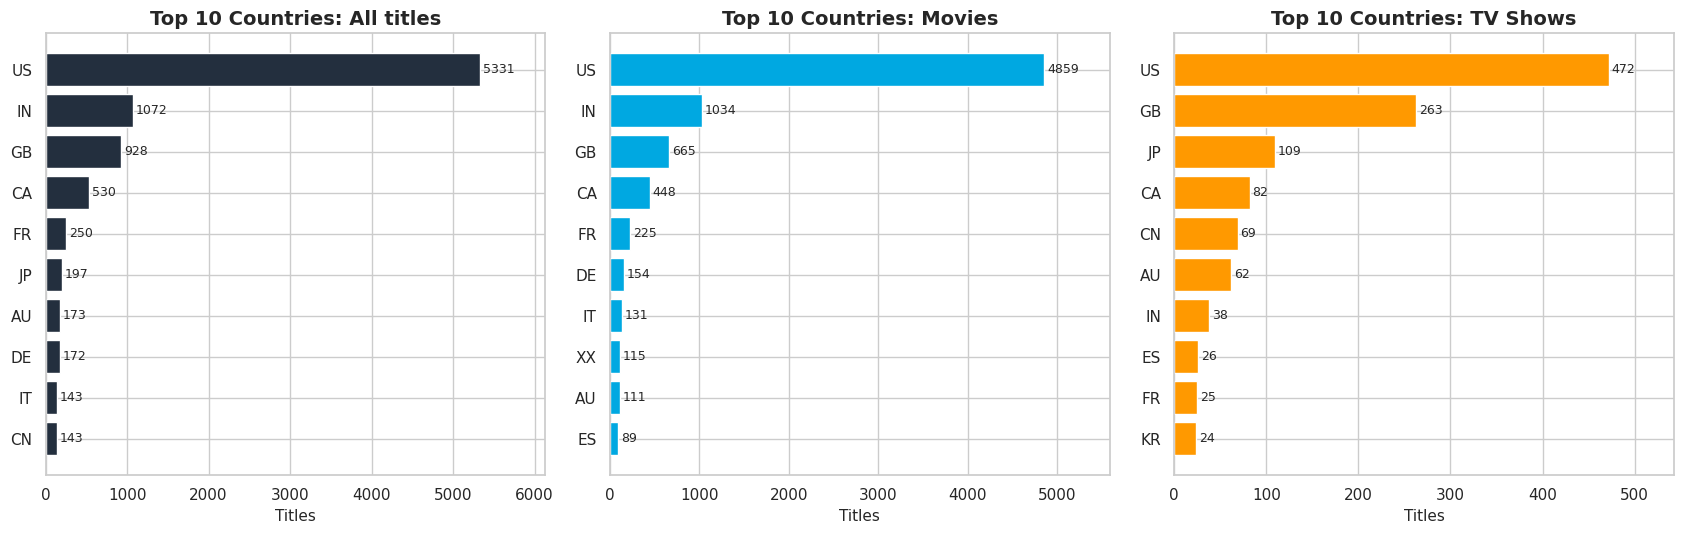

In [22]:
# Chart - 7: Top 10 countries, overall and by type (Task 9)
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
for ax, (label, data, color) in zip(axes, [("All titles", cx, PRIME_NAVY),
                                            ("Movies", cx[cx["type"] == "Movie"], TYPE_COLORS["Movie"]),
                                            ("TV Shows", cx[cx["type"] == "TV Show"], TYPE_COLORS["TV Show"])]):
    top = data["country"].value_counts().head(10).sort_values()
    bars = ax.barh(top.index, top.values, color=color)
    ax.bar_label(bars, padding=2, fontsize=9); ax.set_xlim(0, top.max() * 1.15)
    ax.set_title(f"Top 10 Countries: {label}"); ax.set_xlabel("Titles")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?
Three side-by-side horizontal bar charts (all, movies, shows) answer the question and the movie/show split in one view.

##### 2. What is/are the insight(s) found from the chart?
The **United States produced or co-produced 5,331 titles (54.0%)**. India (1,072), the UK (928), Canada (530) and France (250) follow. For **movies**, India is second (1,034). For **TV shows**, the UK is second (263) followed by Japan (109), Canada and China; India has only **38 shows**. 821 titles have no country.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** India and the UK are clear strengths for movies and shows respectively, and about 76% of Japan's shows are animation.

**Negative / risk:** heavy US dependence limits regional diversity, and India's near-absence in series is a missed opportunity for a very large market.

#### Chart - 8: Year vs Genre Heatmap (Task 10)

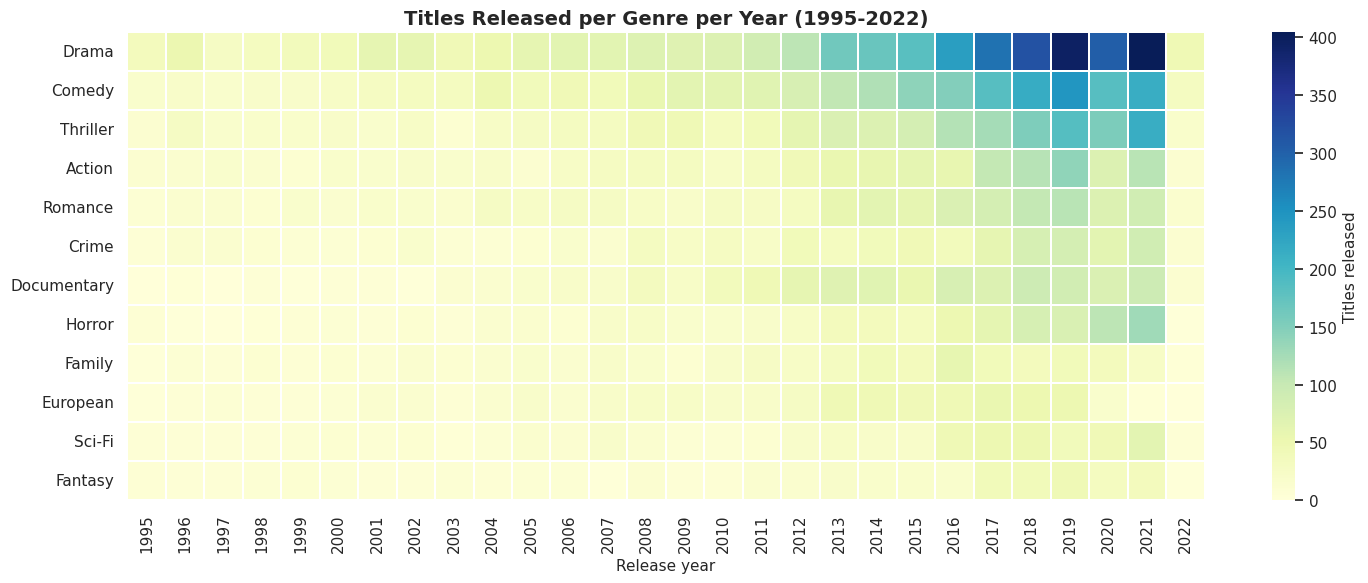

In [23]:
# Chart - 8: Year vs Genre heatmap (Task 10)
top12 = gx["genre"].value_counts().head(12).index
heat = (gx[gx["genre"].isin(top12) & gx["release_year"].between(1995, 2022)]
        .pivot_table(index="genre", columns="release_year", values="id", aggfunc="count", fill_value=0)
        .loc[top12])
fig, ax = plt.subplots(figsize=(15, 6))
sns.heatmap(heat, cmap="YlGnBu", linewidths=0.3, ax=ax, cbar_kws={"label": "Titles released"})
ax.set_title("Titles Released per Genre per Year (1995-2022)"); ax.set_xlabel("Release year"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?
A heatmap shows two categorical/ordinal dimensions (genre and year) and a magnitude (title count) in one compact view.

##### 2. What is/are the insight(s) found from the chart?
Every major genre shows a **steep rise after about 2012**, with Drama and Comedy the darkest cells in the late 2010s, followed by Thriller. The 2022 column is light because 2022 is incomplete.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the growth is broad-based rather than driven by a single genre, so the library keeps a balanced mix.

**Negative / risk:** growth is concentrated in the most competitive genres; smaller genres such as Family, European and Fantasy remain thin in every year.

#### Chart - 9: Release Trend Over Time by Type (Task 11)

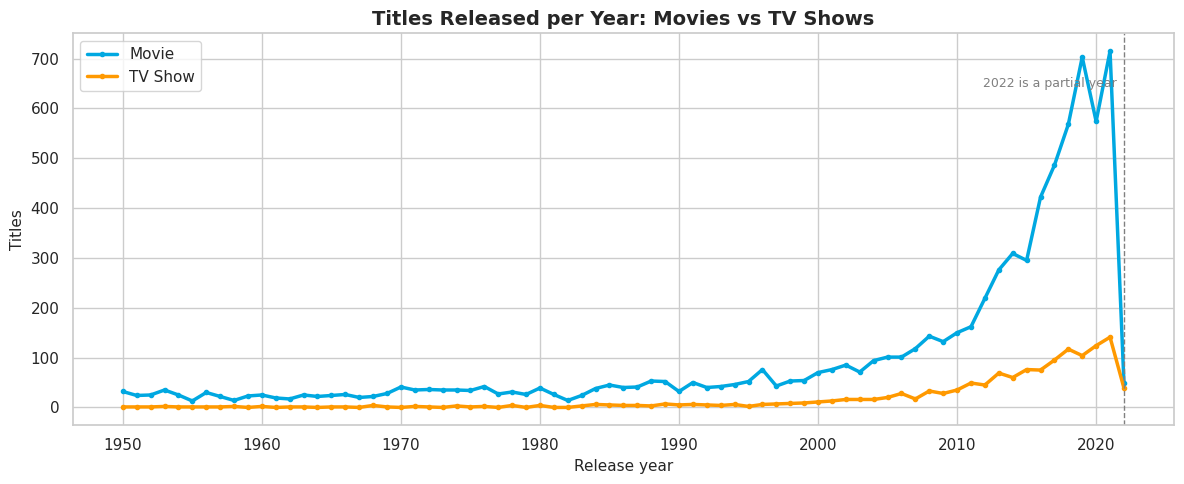

In [24]:
# Chart - 9: Release trend split by type (Task 11)
trend = df.groupby(["release_year", "type"]).size().unstack(fill_value=0)
trend = trend[trend.index >= 1950]
fig, ax = plt.subplots(figsize=(12, 5))
for t in ["Movie", "TV Show"]:
    ax.plot(trend.index, trend[t], label=t, color=TYPE_COLORS[t], lw=2.5, marker="o", markersize=3)
ax.axvline(2022, color="grey", ls="--", lw=1); ax.text(2021.5, trend.max().max() * 0.9, "2022 is a partial year", ha="right", fontsize=9, color="grey")
ax.set_title("Titles Released per Year: Movies vs TV Shows"); ax.set_xlabel("Release year"); ax.set_ylabel("Titles")
ax.legend(title="")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?
A multi-line time series lets the two content types be compared on the same timeline.

##### 2. What is/are the insight(s) found from the chart?
Both lines rise sharply from about 2012. Movies grew from 150 (2010) to 715 (2021) and shows from 35 to 141. The mix barely changed: shows were about 19% of 2010 releases and 16% of 2021 releases, i.e. roughly **one new title in six is a show**. The earliest show dates from 1934.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** steady growth in both formats.

**Negative / risk:** the show share has not increased even as the industry shifts towards series, so Prime has not tilted its catalogue toward the format that drives retention.

#### Chart - 10: Rating Trends Over Time (Task 12)

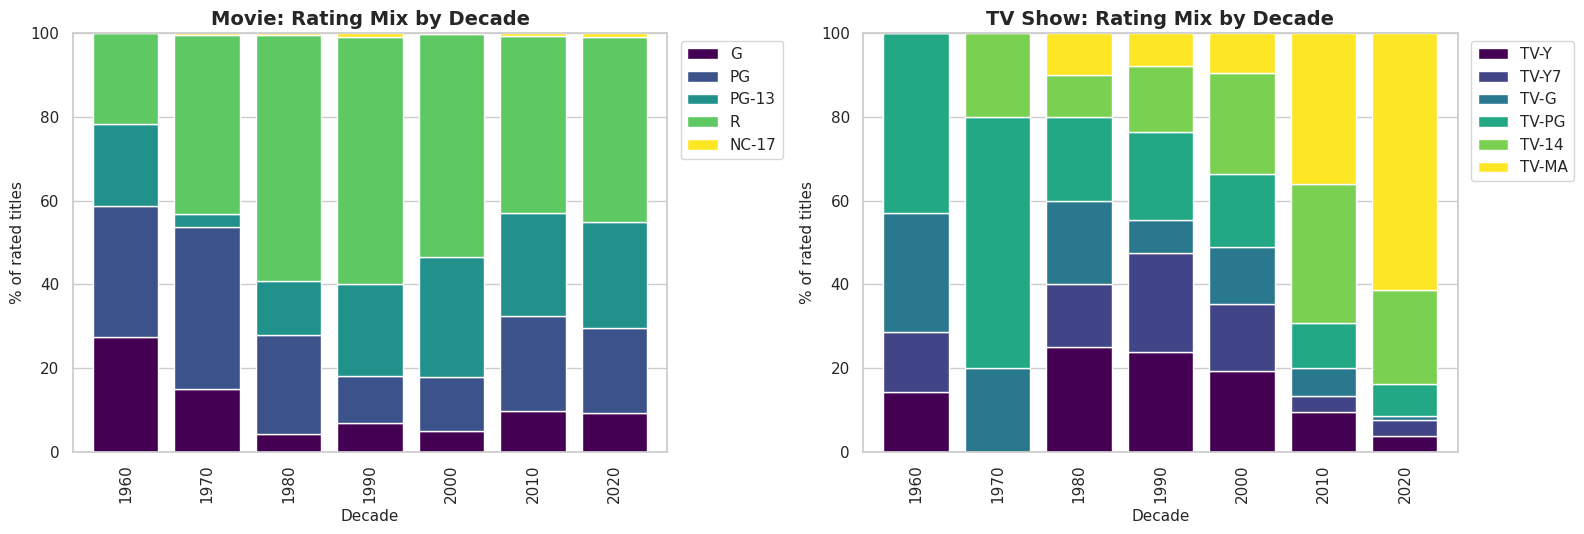

In [25]:
# Chart - 10: Rating trends over time (Task 12)
cert = df[(df["age_certification"] != "Not Rated") & (df["decade"] >= 1960)]
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, (t, order) in zip(axes, [("Movie", MOVIE_RATINGS), ("TV Show", TV_RATINGS)]):
    sub = cert[cert["type"] == t]
    ct = pd.crosstab(sub["decade"], sub["age_certification"]).reindex(columns=order, fill_value=0)
    ct = ct[ct.sum(axis=1) > 0]
    (ct.div(ct.sum(axis=1), axis=0) * 100).plot(kind="bar", stacked=True, ax=ax, colormap="viridis", width=0.8)
    ax.set_title(f"{t}: Rating Mix by Decade"); ax.set_xlabel("Decade"); ax.set_ylabel("% of rated titles")
    ax.legend(title="", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?
100% stacked bars by decade (separately for movies and shows, because they use different rating scales) show how the mix, not the volume, changes.

##### 2. What is/are the insight(s) found from the chart?
For movies, **R share fell from 59.2% (1990s) to 42.3% (2010s)** while PG-13 reached 24.7%. For shows, **TV-MA grew from 9.6% of rated shows in the 2000s to 36.0% in the 2010s**, with TV-14 at 33.3%. Early decades have few rated titles, so they should be read with caution.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** recent series are increasingly mature, in line with prestige-drama demand.

**Negative / risk:** a rising TV-MA share narrows the audience, so family-safe shows need deliberate investment.

#### Chart - 11: Most Credited Directors and Actors, All Time (Task 13)

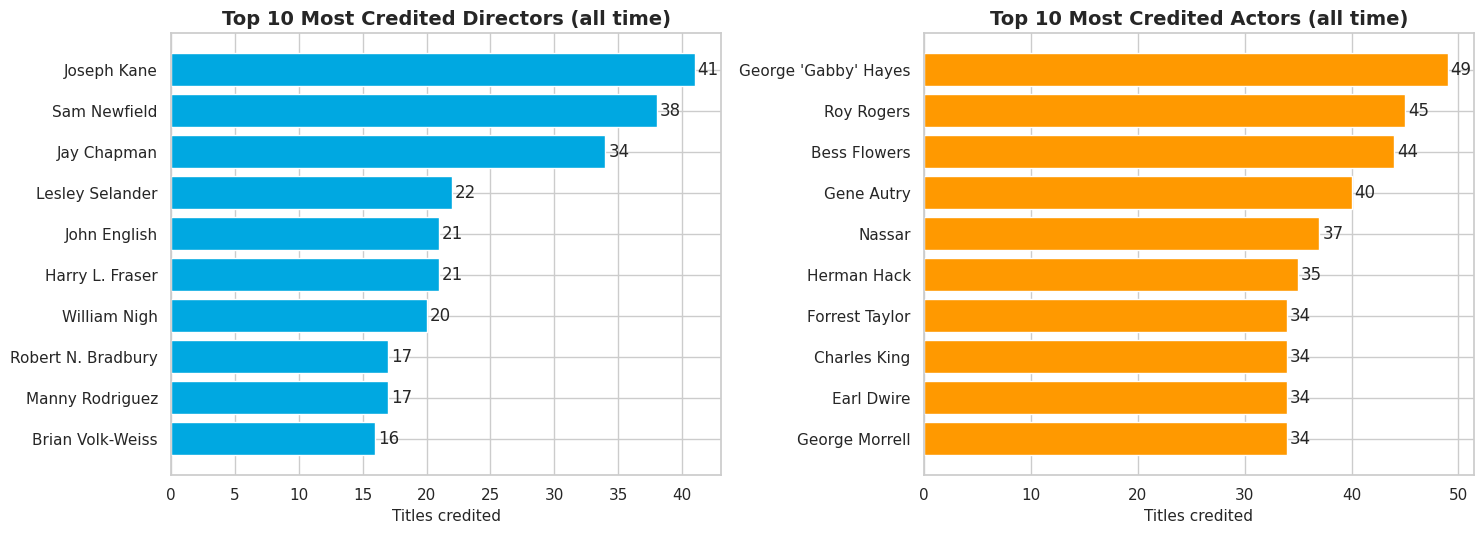

In [26]:
# Chart - 11: Most credited directors and actors (Task 13)
def top_people(role, since=None, n=10):
    c = cred[cred["role"] == role].merge(df[["id", "release_year"]], on="id")
    if since:
        c = c[c["release_year"] >= since]
    return c.groupby("name")["id"].nunique().sort_values(ascending=False).head(n).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, role, color in zip(axes, ["Director", "Actor"], [PRIME_BLUE, PRIME_ORANGE]):
    s = top_people(role)
    bars = ax.barh(s.index, s.values, color=color); ax.bar_label(bars, padding=2)
    ax.set_title(f"Top 10 Most Credited {role}s (all time)"); ax.set_xlabel("Titles credited")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?
Horizontal bars rank people by number of titles; showing directors and actors side by side keeps the comparison simple.

##### 2. What is/are the insight(s) found from the chart?
Top directors: **Joseph Kane (41 titles), Sam Newfield (38) and Jay Chapman (34)**. Top actors: **George 'Gabby' Hayes (49), Roy Rogers (45) and Bess Flowers (44)**. Most of these names belong to the classic-era Hollywood westerns and B-movies, which are likely low-cost library titles.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the data identifies prolific creators who anchor classic collections.

**Negative / risk:** all-time counts are dominated by old catalogue titles, so they are a poor guide for current commissioning (see Chart 12).

#### Chart - 12: Most Credited People in Recent Titles, 2010+

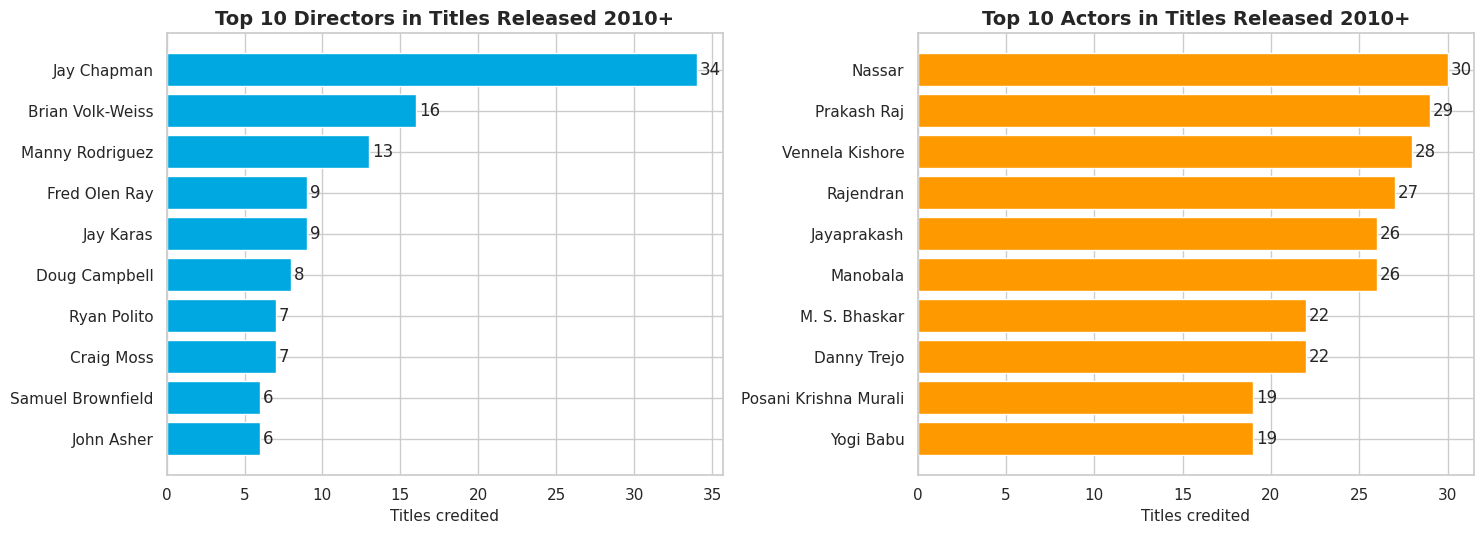

In [27]:
# Chart - 12: Most credited people in recent titles (2010 onwards)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, role, color in zip(axes, ["Director", "Actor"], [PRIME_BLUE, PRIME_ORANGE]):
    s = top_people(role, since=2010)
    bars = ax.barh(s.index, s.values, color=color); ax.bar_label(bars, padding=2)
    ax.set_title(f"Top 10 {role}s in Titles Released 2010+"); ax.set_xlabel("Titles credited")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?
Repeating the ranking for titles released since 2010 removes the old-catalogue bias.

##### 2. What is/are the insight(s) found from the chart?
Recent top directors include **Jay Chapman (34), Brian Volk-Weiss (16) and Manny Rodriguez (13)**. The recent actor list is led by **Nassar (30), Prakash Raj (29) and Vennela Kishore (28)**, mostly Indian (South Indian cinema) names, which is consistent with India's large movie share.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** shows where recent talent relationships are concentrated, useful for regional marketing and deals.

**Negative / risk:** credit counts reflect catalogue volume, not audience pull, so they should be combined with score and popularity before making decisions.

#### Chart - 13: Content Duration Analysis and Outliers (Task 14)

Movie runtime (min)          median=91  mean=94.0  max=549  IQR fence=(42, 142)  outliers=630
Show episode runtime (min)   median=33  mean=35.8  max=153  IQR fence=(-13, 83)  outliers=22
Show seasons                 median=1  mean=2.8  max=51  IQR fence=(-2, 6)  outliers=103


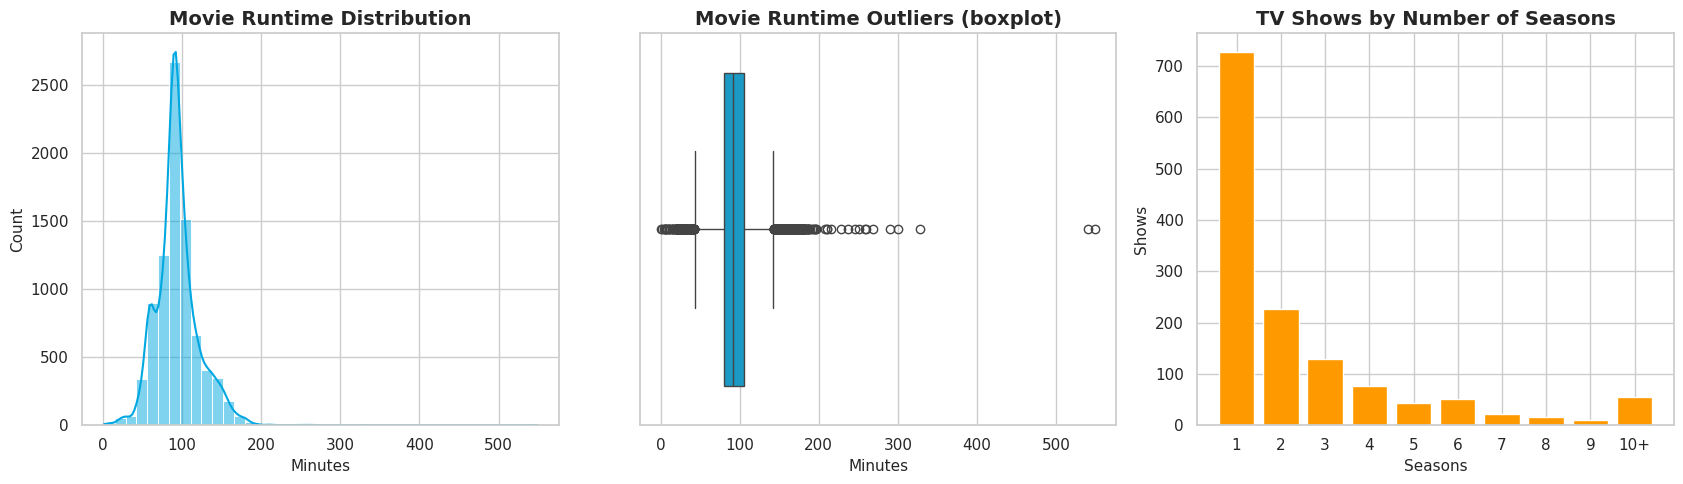

In [28]:
# Chart - 13: Duration analysis & outliers (Task 14)
def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return lo, hi, int(((s < lo) | (s > hi)).sum())

for label, s in [("Movie runtime (min)", movies["runtime"]), ("Show episode runtime (min)", shows["runtime"]),
                 ("Show seasons", shows["seasons"])]:
    lo, hi, n_out = iqr_bounds(s)
    print(f"{label:28s} median={s.median():.0f}  mean={s.mean():.1f}  max={s.max():.0f}  "
          f"IQR fence=({lo:.0f}, {hi:.0f})  outliers={n_out}")

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
sns.histplot(movies["runtime"], bins=40, kde=True, color=PRIME_BLUE, ax=axes[0])
axes[0].set_title("Movie Runtime Distribution"); axes[0].set_xlabel("Minutes")
sns.boxplot(x=movies["runtime"], color=PRIME_BLUE, ax=axes[1])
axes[1].set_title("Movie Runtime Outliers (boxplot)"); axes[1].set_xlabel("Minutes")
seasons = shows["seasons"].clip(upper=10).astype(int).value_counts().sort_index()
axes[2].bar(seasons.index.astype(str).str.replace("10", "10+"), seasons.values, color=PRIME_ORANGE)
axes[2].set_title("TV Shows by Number of Seasons"); axes[2].set_xlabel("Seasons"); axes[2].set_ylabel("Shows")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?
A histogram shows the shape of movie runtimes, a boxplot highlights outliers and a bar chart suits the discrete number of seasons.

##### 2. What is/are the insight(s) found from the chart?
Movies have a median runtime of **91 minutes** (mean 94.0). The IQR rule flags **630 outliers** outside 42 to 142 minutes: 108 movies are under 40 minutes (the minimum is 1 minute, likely a short or clip) and 39 exceed 180 minutes (the longest is 549 minutes). Show episodes have a median of **33 minutes**. **53.6% of shows have only one season**, 29.7% have three or more and the longest has 51 seasons (103 shows exceed the 6-season fence).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** the standard 90 to 100 minute film length is well covered, and long-running shows (7+ seasons) are proven retention anchors.

**Negative / risk:** the many one-season shows suggest cancellations or limited series, and extreme runtimes (1-minute clips, 9-hour compilations) should be filtered in recommendation features so they do not distort results.

#### Chart - 14: IMDb Score by Content Type

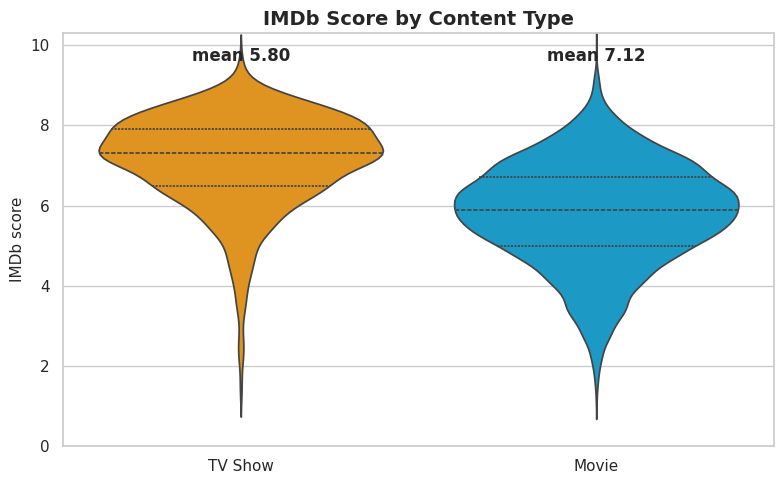

In [29]:
# Chart - 14: IMDb score by content type
fig, ax = plt.subplots(figsize=(8, 5))
sns.violinplot(data=df.dropna(subset=["imdb_score"]), x="type", y="imdb_score", palette=TYPE_COLORS,
               inner="quartile", ax=ax)
means = df.groupby("type")["imdb_score"].mean()
for i, t in enumerate(["Movie", "TV Show"]):
    ax.text(i, 9.6, f"mean {means[t]:.2f}", ha="center", fontweight="bold")
ax.set_ylim(0, 10.3); ax.set_title("IMDb Score by Content Type"); ax.set_xlabel(""); ax.set_ylabel("IMDb score")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?
A violin plot shows the full distribution of scores, not only the average.

##### 2. What is/are the insight(s) found from the chart?
TV shows have a clearly higher average IMDb score (**7.12**) than movies (**5.8**); TMDB shows the same gap (7.32 vs 5.79). Scores are missing for 14.1% of shows and 9.8% of movies.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** shows are a quality advantage and a strong argument for investing in more series.

**Negative / risk:** the gap may partly come from selection (only well-known shows get many votes) and from the large pool of low-budget movies, so it should not be read as a causal effect.

#### Chart - 15 - Correlation Heatmap

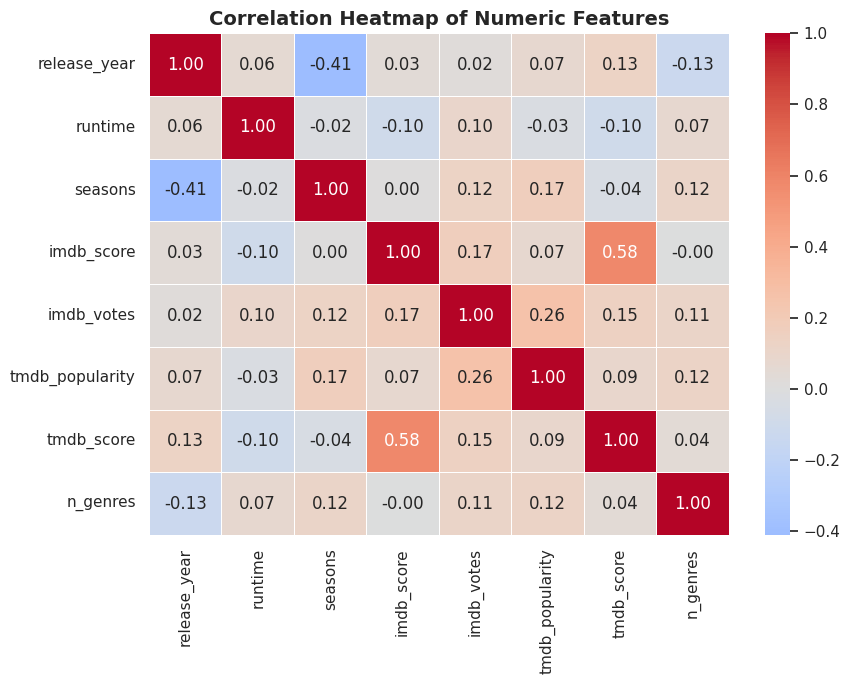

In [30]:
# Chart - 15: Correlation heatmap
num_cols = ["release_year", "runtime", "seasons", "imdb_score", "imdb_votes", "tmdb_popularity", "tmdb_score", "n_genres"]
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5, ax=ax)
ax.set_title("Correlation Heatmap of Numeric Features")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?
A correlation heatmap quickly shows which numeric variables move together and whether any pair is redundant.

##### 2. What is/are the insight(s) found from the chart?
IMDb and TMDB scores are moderately correlated (**0.58**), so they measure similar but not identical sentiment. Runtime is only weakly related to IMDb score (-0.1), vote count to IMDb score is 0.17, and release year to TMDB score is 0.13. No strong relationship exists between duration, age or popularity and rating.

#### Chart - 16 - Pair Plot

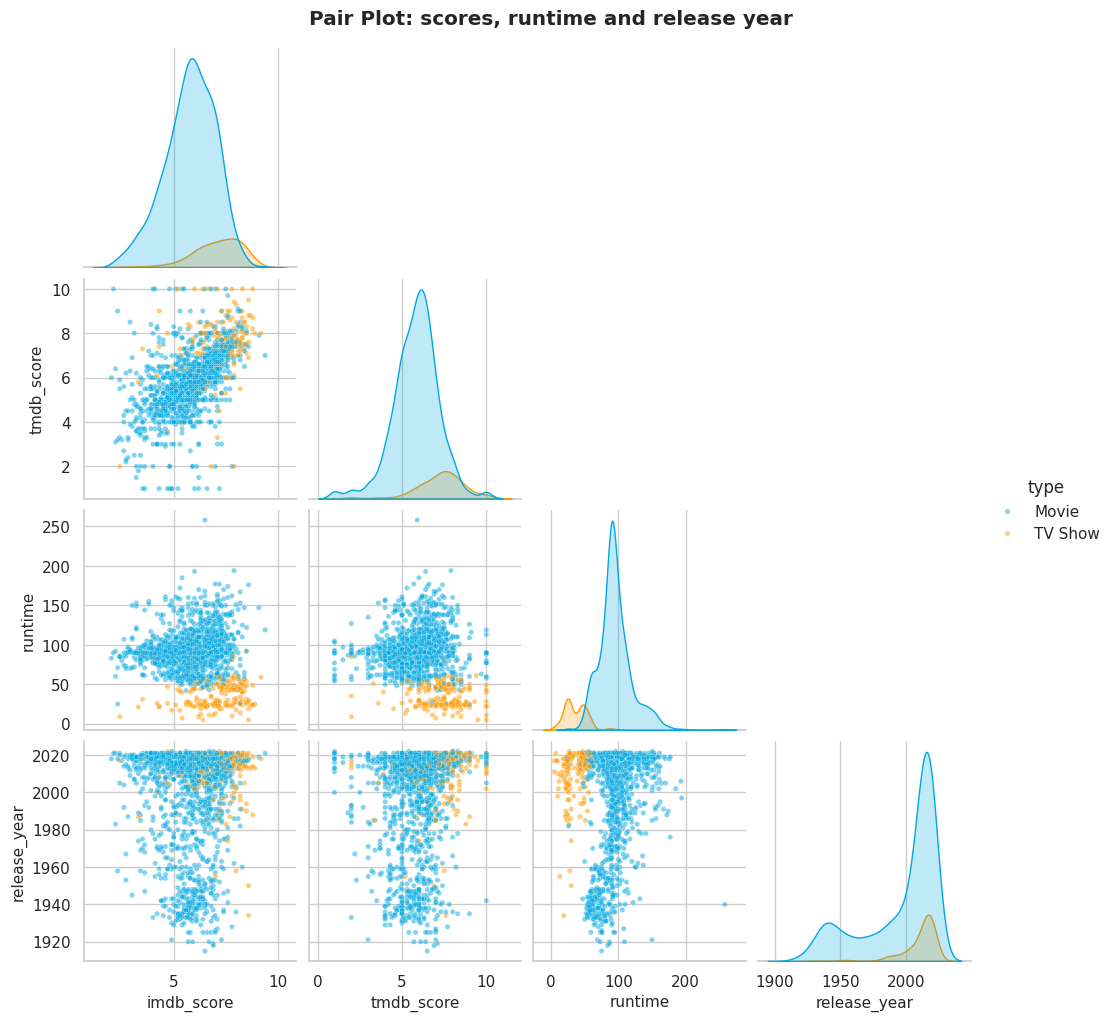

In [31]:
# Chart - 16: Pair plot
sample = df[["imdb_score", "tmdb_score", "runtime", "release_year", "type"]].dropna().sample(1500, random_state=42)
g = sns.pairplot(sample, hue="type", palette=TYPE_COLORS, corner=True,
                 plot_kws={"alpha": 0.5, "s": 14}, diag_kind="kde")
g.fig.suptitle("Pair Plot: scores, runtime and release year", y=1.02, fontweight="bold")
plt.show()

##### 1. Why did you pick the specific chart?
A pair plot shows every pairwise relationship and the distribution of each variable, split by content type.

##### 2. What is/are the insight(s) found from the chart?
Runtime separates the two types very well (shows cluster at short episode lengths), while IMDb and TMDB scores overlap strongly and are positively related. Release year is heavily skewed to recent years. This foreshadows the ML result: **runtime is the strongest signal for predicting content type**.

#### Chart - 17: Word Cloud of Title Words (Task 15, bonus)

[('love', 151), ('man', 95), ('story', 89), ('christmas', 79), ('night', 74), ('last', 66), ('black', 66), ('girl', 64), ('life', 64), ('time', 64), ('house', 59), ('world', 58), ('big', 52), ('american', 52), ('new', 52)]


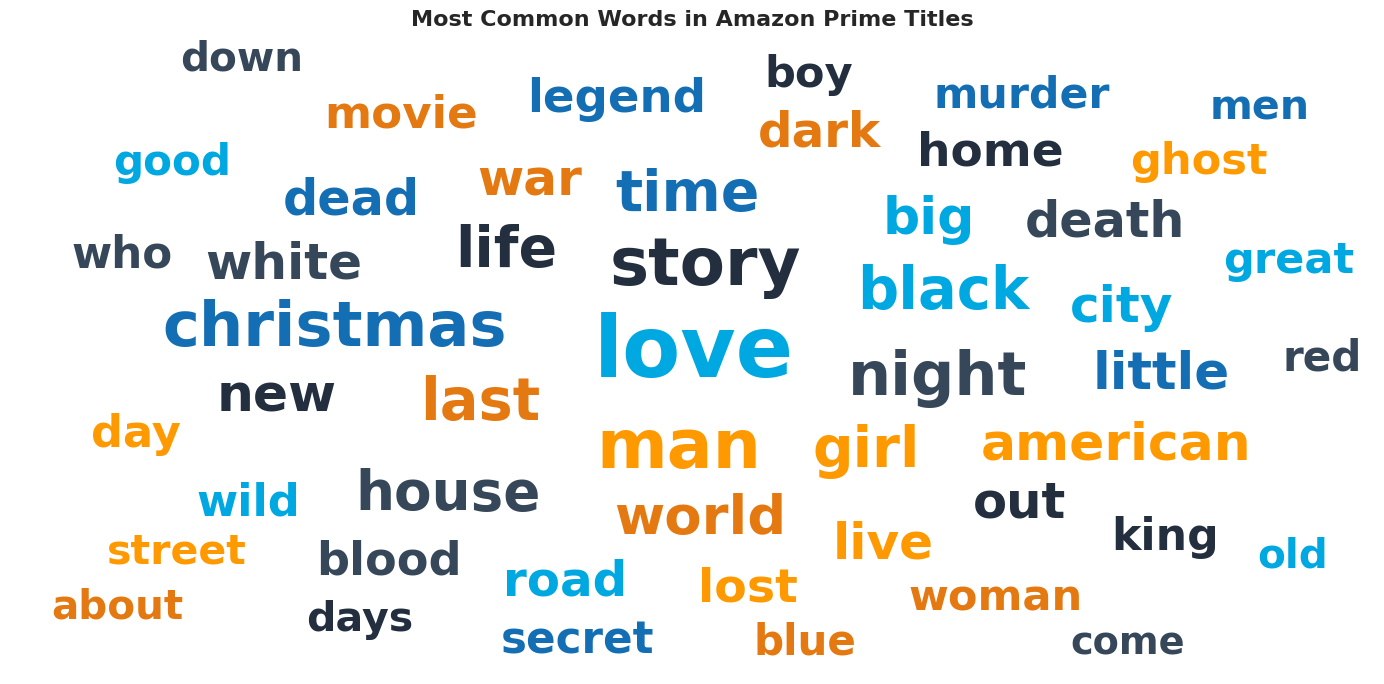

In [32]:
# Chart - 17: Word cloud of title words (Task 15, bonus)
# The wordcloud package is not always installed, so a small self-contained version is used here.
STOPWORDS = set("the a an of and in to for on at with from by is are my your our his her their its into "
                "all you me we it as be or no not this that vs part one two".split())
word_freq = Counter(w for t in df["title"].str.lower() for w in re.findall(r"[a-z']{3,}", t) if w not in STOPWORDS)

def simple_wordcloud(freqs, n=70, figsize=(14, 7), seed=3):
    """Place the n most frequent words along an expanding spiral without overlaps."""
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xlim(-100, 100); ax.set_ylim(-50, 50); ax.axis("off")
    fig.canvas.draw(); renderer = fig.canvas.get_renderer()
    colors = [PRIME_BLUE, PRIME_ORANGE, PRIME_NAVY, "#146EB4", "#37475A", "#E47911"]
    items = freqs.most_common(n); top = items[0][1]; placed = []
    for i, (word, f) in enumerate(items):
        size = 11 + 50 * (f / top) ** 0.6
        for step in range(1, 900):
            theta = step * 0.35; r = 0.35 * theta
            x, y = 2.1 * r * np.cos(theta), r * np.sin(theta)
            t = ax.text(x, y, word, fontsize=size, ha="center", va="center", color=colors[i % len(colors)],
                        fontweight="bold")
            bb = t.get_window_extent(renderer).transformed(ax.transData.inverted())
            inside = bb.x0 > -100 and bb.x1 < 100 and bb.y0 > -50 and bb.y1 < 50
            clash = any(not (bb.x1 < p.x0 or bb.x0 > p.x1 or bb.y1 < p.y0 or bb.y0 > p.y1) for p in placed)
            if inside and not clash:
                placed.append(bb); break
            t.remove()
    ax.set_title("Most Common Words in Amazon Prime Titles", fontsize=16, fontweight="bold")
    return fig

simple_wordcloud(word_freq); plt.tight_layout(); plt.show()
print(word_freq.most_common(15))

##### 1. Why did you pick the specific chart?
A word cloud gives a fast, intuitive view of recurring themes in titles.

##### 2. What is/are the insight(s) found from the chart?
The most frequent title words are **love, man, story, christmas, night, last, black, girl**. *Love* (151 titles) and *Christmas* (79) stand out as strong themes.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** recurring themes such as romance and Christmas can drive thematic collections and seasonal marketing.

**Negative / risk:** title words are only a rough proxy for content; they should support, not replace, genre data.

#### Chart - 18: Genres of Titles Containing "Love", "War" or "Christmas" (Task 15)

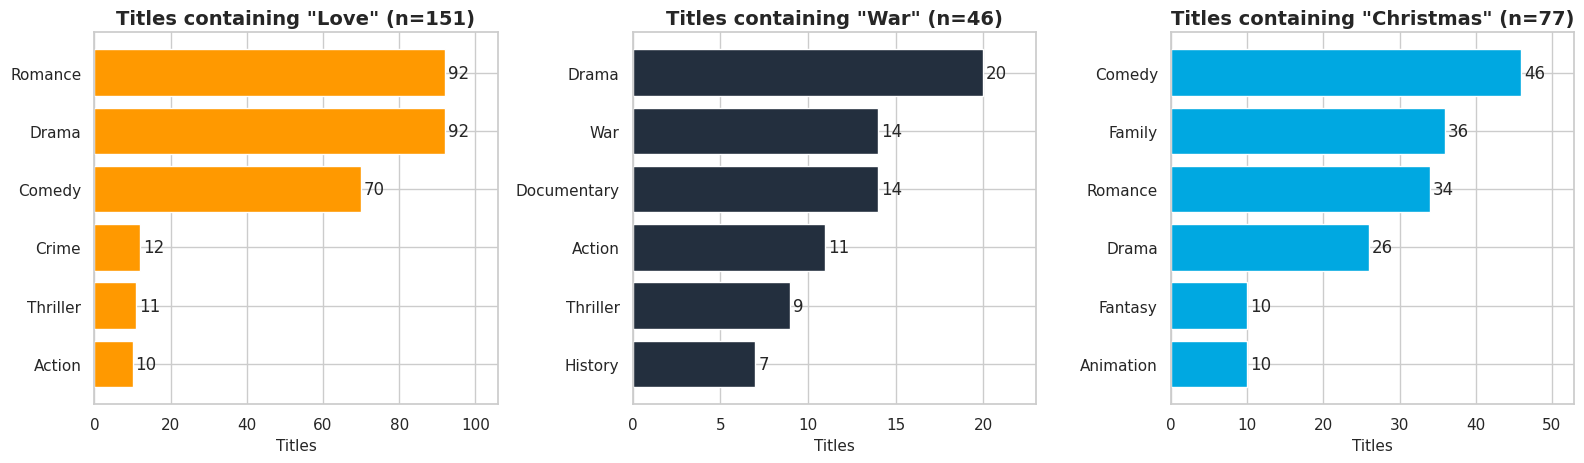

In [33]:
# Chart - 18: Genres of titles containing "Love", "War" or "Christmas" (Task 15)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, word, color in zip(axes, ["love", "war", "christmas"], [PRIME_ORANGE, PRIME_NAVY, PRIME_BLUE]):
    subset = gx[gx["title"].str.lower().str.contains(rf"\b{word}\b", regex=True)]
    top = subset["genre"].value_counts().head(6).sort_values()
    bars = ax.barh(top.index, top.values, color=color); ax.bar_label(bars, padding=2)
    ax.set_xlim(0, top.max() * 1.15)
    ax.set_title(f'Titles containing "{word.title()}" (n={subset["id"].nunique()})'); ax.set_xlabel("Titles")
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?
Small bar charts per keyword show what genres these themes belong to.

##### 2. What is/are the insight(s) found from the chart?
**Love** (151 titles) is led by Drama (92), Romance (92) and Comedy (70). **War** (46 titles) is spread over Drama (20), Documentary (14), War and Action. **Christmas** (77 titles) is mainly Comedy (46), Family (36) and Romance (34).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** Christmas content is family-comedy-romance, so a seasonal row can target households; war titles suit documentary and history audiences.

**Negative / risk:** Christmas content is highly seasonal, so its value falls outside November and December.

## **5. Solution to Business Objective** (Tasks 16 and 17)

### Key findings (Task 16)
1. **Movie-heavy catalogue:** 86.2% movies vs 13.8% shows; the mix has not shifted over time.
2. **Recent growth:** 60.4% of titles are from 2010 or later; releases peaked at 856 in 2021.
3. **Genres:** Drama (4,762) and Comedy (2,987) lead; shows over-index on animation, documentary, family and reality.
4. **Geography:** the US is 54.0% of titles; India is strong in movies (1,034) but weak in shows (38); the UK and Japan are strong for shows.
5. **Ratings:** 65.7% of titles are unrated; rated content skews mature (R, TV-MA, TV-14) and TV-MA is growing fast.
6. **Quality:** shows average 7.12 on IMDb vs 5.8 for movies.
7. **Duration:** movies centre on 91 minutes; 53.6% of shows have a single season.

### Recommendations for Amazon Prime (Task 17)
* **Content type strategy:** raise the share of series, especially multi-season ones, to improve retention; use the higher show scores in marketing.
* **Region-based acquisition:** build Indian-language series (India has 1,034 movies but 38 shows) and acquire more UK and Japanese series and animation.
* **Genre-focused production:** keep Drama and Comedy as the base but differentiate; add binge-worthy thriller/crime series and expand family and animation, where shows already over-index.
* **Content rating considerations:** complete the missing age certifications (about two thirds of titles), keep a balance between mature and family content, and use Christmas and love-themed collections for seasonal campaigns.
* **Data and curation:** filter extreme runtimes and curate the pre-1980 back-catalogue so low-engagement titles do not dilute recommendations.

## **6. Dashboard (Task 18, bonus)**

A Streamlit dashboard is provided in `app.py`. It reads `titles_cleaned.csv` and offers filters for content type, release years, genre and country, with KPI cards and charts that update interactively.

```bash
pip install streamlit pandas
streamlit run app.py
```

## ***7. Predictive Modeling (Task 19, bonus): Movie vs TV Show***

**Goal:** predict whether a title is a Movie or a TV Show from its attributes (runtime, genres, rating, scores, release year).

**Design choices**
* `seasons` is excluded because it exists only for shows (it would leak the answer).
* Age certification is also a near-perfect signal, since movies and shows use different rating systems. Models are therefore evaluated **with and without** rating features.
* The target is imbalanced (about 86% movies), so class weights / sample weights are used and **F1 for the TV Show class** and ROC-AUC are reported alongside accuracy.

In [34]:
# Task 19 (bonus): predict Movie vs TV Show
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay)

# Feature engineering. NOTE: `seasons` is deliberately excluded because it only exists for shows (target leakage).
top_genres_ml = gx["genre"].value_counts().head(20).index
genre_flags = pd.DataFrame({f"genre_{g}": df["genres_list"].apply(lambda x, g=g: int(g in x)) for g in top_genres_ml})
rating_flags = pd.get_dummies(df["age_certification"], prefix="rating").astype(int)
num_feats = df[["runtime", "release_year", "imdb_score", "imdb_votes", "tmdb_score", "tmdb_popularity", "n_genres"]]

X_full = pd.concat([num_feats, genre_flags, rating_flags], axis=1)
X_norating = X_full.drop(columns=rating_flags.columns)          # variant without age certification
y = (df["type"] == "TV Show").astype(int)                        # 1 = TV Show, 0 = Movie
print("Feature matrix:", X_full.shape, "| without ratings:", X_norating.shape)
print("Class balance:", y.value_counts(normalize=True).round(3).to_dict(), "(1 = TV Show)")

Feature matrix: (9868, 38) | without ratings: (9868, 26)
Class balance: {0: 0.862, 1: 0.138} (1 = TV Show)


In [35]:
# Train / evaluate three models (stratified 80/20 split, class imbalance handled)
def make_models():
    return {
        "Logistic Regression": Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()),
                                         ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
        "Random Forest": Pipeline([("imp", SimpleImputer(strategy="median")),
                                   ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                                  random_state=42, n_jobs=-1))]),
        "Gradient Boosting": Pipeline([("imp", SimpleImputer(strategy="median")),
                                       ("clf", GradientBoostingClassifier(random_state=42))]),
    }

def evaluate(X, label):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
    rows, fitted = [], {}
    for name, model in make_models().items():
        if name == "Gradient Boosting":                       # GB has no class_weight -> use sample weights
            model.fit(X_tr, y_tr, clf__sample_weight=compute_sample_weight("balanced", y_tr))
        else:
            model.fit(X_tr, y_tr)
        pred, proba = model.predict(X_te), model.predict_proba(X_te)[:, 1]
        rows.append({"features": label, "model": name, "accuracy": accuracy_score(y_te, pred),
                     "precision (TV)": precision_score(y_te, pred), "recall (TV)": recall_score(y_te, pred),
                     "f1 (TV)": f1_score(y_te, pred), "roc_auc": roc_auc_score(y_te, proba)})
        fitted[name] = model
    return pd.DataFrame(rows), fitted, (X_tr, X_te, y_tr, y_te)

res_full, models_full, split_full = evaluate(X_full, "with ratings")
res_nr, models_nr, split_nr = evaluate(X_norating, "without ratings")
results = pd.concat([res_full, res_nr], ignore_index=True)
results.round(3)

,features,model,accuracy,precision (TV),recall (TV),f1 (TV),roc_auc
0,with ratings,Logistic Regression,0.961,0.788,0.985,0.875,0.995
1,with ratings,Random Forest,0.984,0.938,0.945,0.941,0.996
2,with ratings,Gradient Boosting,0.963,0.794,0.982,0.878,0.995
3,without ratings,Logistic Regression,0.951,0.740,0.989,0.847,0.990
4,without ratings,Random Forest,0.977,0.919,0.915,0.917,0.994
5,without ratings,Gradient Boosting,0.957,0.768,0.989,0.865,0.994


### Model results

* **Random Forest is the best model** in both settings: F1 = **0.941** with ratings and **0.917** without ratings (accuracy 0.984 and 0.977).
* Logistic Regression and Gradient Boosting reach a high recall for shows (0.989 and 0.989) but lower precision (0.74 and 0.768): they label too many movies as shows because the class weights push them to favour the minority class. Their F1 is 0.847 and 0.865.
* Removing rating features reduces F1 only slightly, so the model does not rely on the rating shortcut.

In [36]:
# 5-fold stratified cross-validation (F1 for the minority class = TV Show), features WITHOUT ratings
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = {name: cross_val_score(m, X_norating, y, cv=cv, scoring="f1", n_jobs=-1)
             for name, m in make_models().items() if name != "Gradient Boosting"}
for name, s in cv_scores.items():
    print(f"{name:20s} CV F1 = {s.mean():.3f} (+/- {s.std():.3f})")

Logistic Regression  CV F1 = 0.842 (+/- 0.013)
Random Forest        CV F1 = 0.894 (+/- 0.019)


In [37]:
# Hyper-parameter tuning of the Random Forest (RandomizedSearchCV, features without ratings)
X_tr, X_te, y_tr, y_te = split_nr
param_dist = {"clf__n_estimators": [200, 300, 500], "clf__max_depth": [None, 10, 20],
              "clf__min_samples_leaf": [1, 2, 4], "clf__max_features": ["sqrt", 0.5]}
search = RandomizedSearchCV(make_models()["Random Forest"], param_dist, n_iter=8, cv=3, scoring="f1",
                            random_state=42, n_jobs=-1)
search.fit(X_tr, y_tr)
best_rf = search.best_estimator_
baseline_rf = models_nr["Random Forest"]                       # default Random Forest from the previous step
base_f1  = f1_score(y_te, baseline_rf.predict(X_te))
tuned_f1 = f1_score(y_te, best_rf.predict(X_te))
print("Best params :", search.best_params_)
print(f"Default RF -> F1 {base_f1:.3f} | Tuned RF -> F1 {tuned_f1:.3f} "
      f"(ROC-AUC {roc_auc_score(y_te, best_rf.predict_proba(X_te)[:, 1]):.3f})")

# Keep whichever version scores better on the hold-out test set
final_model = best_rf if tuned_f1 >= base_f1 else baseline_rf
print("Final model chosen:", "tuned Random Forest" if final_model is best_rf else "default Random Forest")
pred = final_model.predict(X_te)

Best params : {'clf__n_estimators': 500, 'clf__min_samples_leaf': 2, 'clf__max_features': 'sqrt', 'clf__max_depth': None}
Default RF -> F1 0.917 | Tuned RF -> F1 0.898 (ROC-AUC 0.994)
Final model chosen: default Random Forest


### Cross-validation and tuning

* 5-fold CV F1: Random Forest **0.894 (+/- 0.019)** vs Logistic Regression **0.842 (+/- 0.013)**, so the ranking is stable.
* `RandomizedSearchCV` (8 candidates, 3-fold, scoring F1) found {'n_estimators': 500, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': None}. On the hold-out test set the tuned model scored an F1 of 0.898 against 0.917 for the default Random Forest, so **tuning did not help** and the **default Random Forest** is kept as the final model. This is a useful reminder that tuned models should always be compared with the baseline on unseen data.

Top features: ['runtime', 'imdb_score', 'tmdb_score', 'release_year', 'tmdb_popularity']


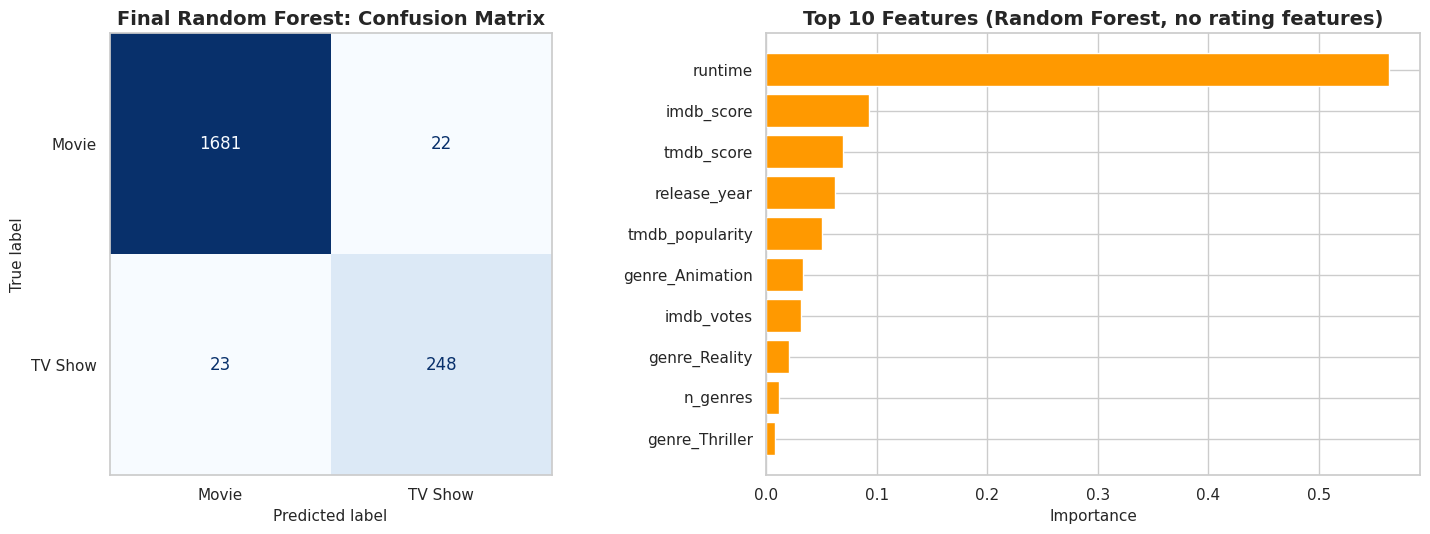

In [38]:
# Confusion matrix and feature importance of the final Random Forest
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=["Movie", "TV Show"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Final Random Forest: Confusion Matrix"); axes[0].grid(False)
imp = pd.Series(final_model.named_steps["clf"].feature_importances_, index=X_norating.columns).sort_values().tail(10)
bars = axes[1].barh(imp.index, imp.values, color=PRIME_ORANGE)
axes[1].set_title("Top 10 Features (Random Forest, no rating features)"); axes[1].set_xlabel("Importance")
plt.tight_layout(); plt.show()
print("Top features:", list(imp.index[::-1][:5]))

### Final model, explainability and business impact

* **Final model: default Random Forest** (no rating features): accuracy **0.977**, precision **0.919**, recall **0.915**, F1 **0.917**, ROC-AUC **0.994**.
* **Feature importance:** `runtime` is by far the most important (0.564), followed by `imdb_score` (0.093), `tmdb_score` (0.07), `release_year` (0.063) and `tmdb_popularity` (0.051). Shows are short episodes, so runtime separates the types.
* **Business meaning:** high recall means few shows are missed; high precision means few movies are wrongly tagged as shows. The model can automatically fix wrong or missing `type` labels and categorise newly acquired titles that arrive without metadata.

### Save the best model and run a sanity check on unseen rows

In [39]:
# Save the final model and reload it for a sanity check
import joblib
joblib.dump(final_model, "prime_type_classifier.joblib")
loaded = joblib.load("prime_type_classifier.joblib")
sample_rows = X_te.iloc[:5]
print("Predictions:", ["TV Show" if p else "Movie" for p in loaded.predict(sample_rows)])
print("Actual     :", ["TV Show" if p else "Movie" for p in y_te.iloc[:5]])

Predictions: ['Movie', 'Movie', 'Movie', 'Movie', 'Movie']
Actual     : ['Movie', 'Movie', 'TV Show', 'Movie', 'Movie']


# **Conclusion**

The Amazon Prime catalogue (9,868 unique titles) is **large, recent and movie-heavy**. Growth since 2012 has been broad across genres, but the format mix has stayed at roughly six movies per show. Drama and Comedy anchor the library, the US supplies 54.0% of titles, India is a major movie source with almost no series, and the UK and Japan contribute most non-US shows. Ratings metadata is the biggest data-quality weakness (65.7% missing), and rated content skews mature. TV shows score higher than movies on both IMDb and TMDB.

The recommendations are therefore to **grow multi-season series, build Indian-language and UK/Japanese series, strengthen family and animation content, complete age-certification metadata and use seasonal collections**. As a bonus, a Random Forest classifier predicts content type with an F1 of 0.917 and a Streamlit dashboard allows interactive exploration of the cleaned data.

### ***Hurrah! You have successfully completed your EDA Capstone Project !!!***